### objective 5

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error
import joblib
import os

os.makedirs("../models", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)

In [2]:
df = pd.read_csv("../data/processed/punjab_dataset.csv")

features = [c for c in df.columns if "_JJAS" in c and "PUNJAB" not in c]
X = df[features]
y = df["PUNJAB_JJAS"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [3]:
# MLP without PCA
mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(10,), max_iter=2000,
                 alpha=0.01, solver="lbfgs", random_state=42))
mlp.fit(X_train, y_train)
pred1 = mlp.predict(X_test)

In [4]:
# MLP with PCA
pca_mlp = make_pipeline(
    StandardScaler(),
    PCA(n_components=3),
    MLPRegressor(hidden_layer_sizes=(10,), max_iter=2000,
                 alpha=0.01, solver="lbfgs", random_state=42)
)
pca_mlp.fit(X_train, y_train)
pred2 = pca_mlp.predict(X_test)

In [5]:
# Compare models
results = [
    ["MLP", r2_score(y_test, pred1), mean_absolute_error(y_test, pred1)],
    ["PCA+MLP", r2_score(y_test, pred2), mean_absolute_error(y_test, pred2)]
]

comparison = pd.DataFrame(results, columns=["Model", "R2", "MAE"])
print(comparison)
comparison.to_csv("../models/obj5_comparison.csv", index=False)
joblib.dump(mlp, "../models/obj5_mlp_no_pca.pkl")
joblib.dump(pca_mlp, "../models/obj5_mlp_pca.pkl")

     Model        R2        MAE
0      MLP -0.278596  93.035406
1  PCA+MLP  0.505706  77.119935


['../models/obj5_mlp_pca.pkl']

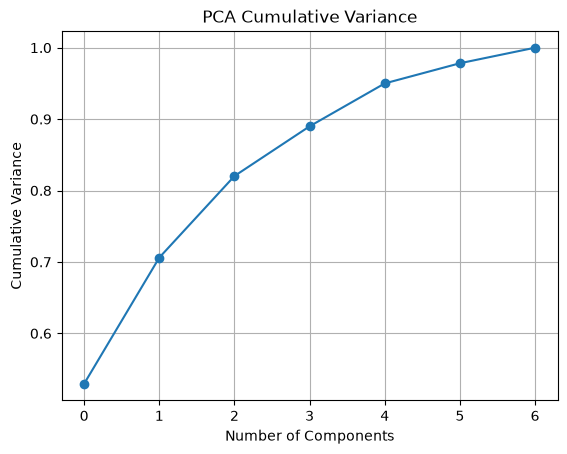

In [6]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA().fit(X_scaled)

plt.plot(pca.explained_variance_ratio_.cumsum(), marker="o")
plt.title("PCA Cumulative Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.grid()
plt.show()
plt.savefig("../reports/figures/obj5_pca_variance.png")
plt.close()

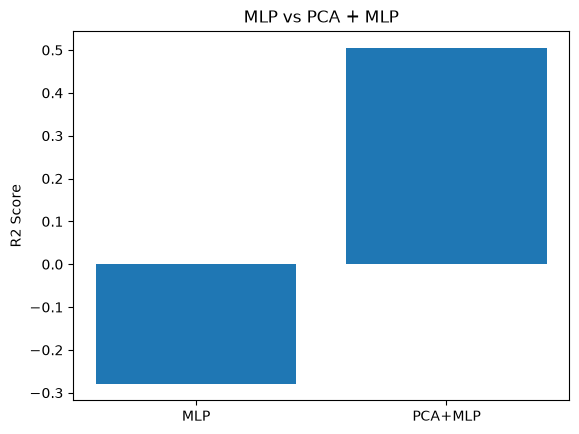

In [7]:
# R2 comparison plot
plt.bar(comparison["Model"], comparison["R2"])
plt.title("MLP vs PCA + MLP")
plt.ylabel("R2 Score")
plt.show()
plt.savefig("../reports/figures/obj5_mlp_compare.png")
plt.close()